In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure notebook plots
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
ames_data = pd.read_csv("ames_data.csv")

ames_data.head()

,Order,PID,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,...,Pool_Area,Pool_QC,Fence,Misc_Feature,Misc_Val,Mo_Sold,Yr_Sold,Sale_Type,Sale_Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,204900
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,95300
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,181900
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254100
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,199700


In [3]:
print(f"Number of observations: {ames_data.shape[0]}")
print(f"Number of variables: {ames_data.shape[1]}")

Number of observations: 2000
Number of variables: 82


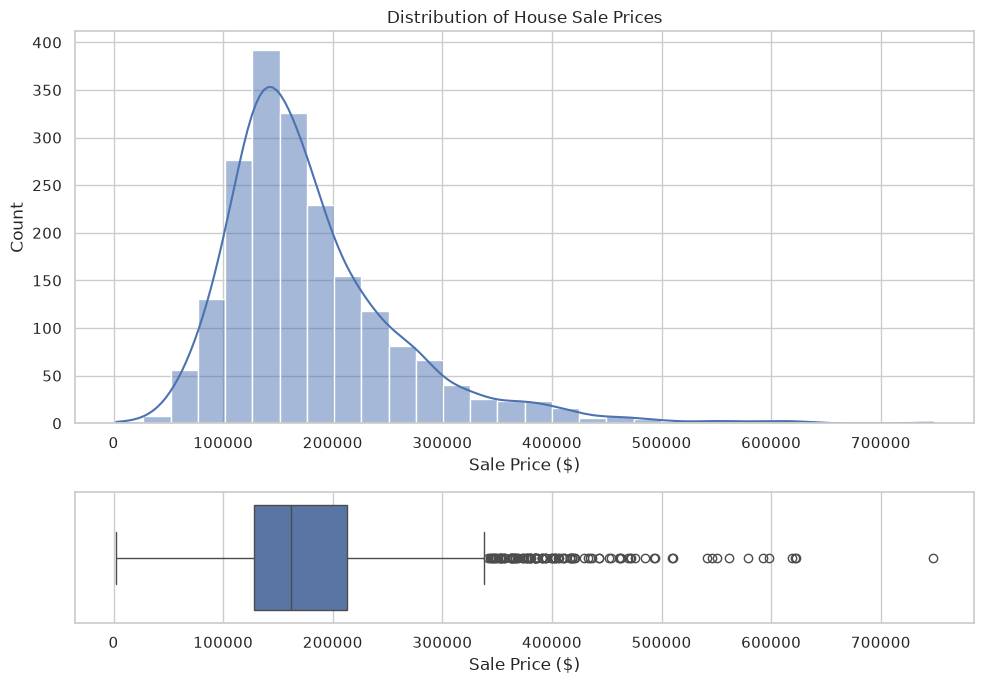

In [4]:
# Visualize the distribution of SalePrice
fig, axes = plt.subplots(
    nrows=2,
    figsize=(10, 7),
    gridspec_kw={"height_ratios": [3, 1]}
)

# Histogram
sns.histplot(
    data=ames_data,
    x="SalePrice",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of House Sale Prices")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Count")

# Boxplot
sns.boxplot(
    data=ames_data,
    x="SalePrice",
    ax=axes[1]
)

axes[1].set_xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

In [5]:
ames_data["SalePrice"].describe()

count      2000.000000
mean     180775.897500
std       81581.671741
min        2489.000000
25%      128600.000000
50%      162000.000000
75%      213125.000000
max      747800.000000
Name: SalePrice, dtype: float64

## Question 1

In [6]:
# Question 1a

q1a_1 = True
q1a_2 = True
q1a_3 = True

print(f"1. {q1a_1}")
print(f"2. {q1a_2}")
print(f"3. {q1a_3}")

1. True
2. True
3. True


<function matplotlib.pyplot.show(close=None, block=None)>

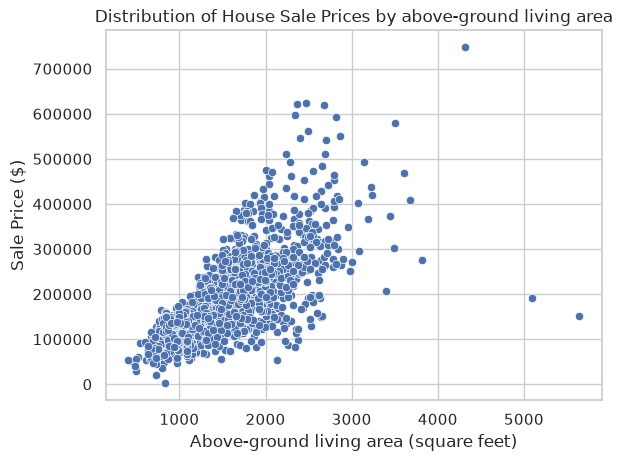

In [7]:
# Question 1b
sns.scatterplot(data=ames_data, x="Gr_Liv_Area", y="SalePrice")

plt.title("Distribution of House Sale Prices by above-ground living area")
plt.ylabel("Sale Price ($)")
plt.xlabel("Above-ground living area (square feet)")

plt.show

In [8]:
# Question 1c
potential_outliers = ames_data.loc[
    ames_data["Gr_Liv_Area"] > 5000,
    ["PID", "SalePrice", "Gr_Liv_Area"]
]

potential_outliers

,PID,SalePrice,Gr_Liv_Area
1014,908154235,152200,5642
1471,908154195,190950,5095


In [9]:
# Question 1d
def remove_outliers(data, variable, lower=-np.inf, upper=np.inf):
    """Return observations strictly between lower and upper limits."""
    
    # Write your code here.
    return data[(data[variable] > lower) & (data[variable] < upper)].copy()

In [10]:
# Verification - do not modify
ames_without_outliers = remove_outliers(
    ames_data,
    "Gr_Liv_Area",
    upper=5000
)

print(f"Q1d Answer - Original observations: {len(ames_data)}")
print(f"Observations after filtering: {len(ames_without_outliers)}")
print(
    "All remaining Gr_Liv_Area values below 5000:",
    (ames_without_outliers["Gr_Liv_Area"] < 5000).all()
)

Q1d Answer - Original observations: 2000
Observations after filtering: 1998
All remaining Gr_Liv_Area values below 5000: True


## Question 2

In [11]:
# Question 2a
def add_total_bathrooms(data):
    """Return a copy of data with a total_bathrooms feature."""
    
    # Make a copy of the input DataFrame.
    with_bathrooms = data.copy()
    
    # Define the bathroom columns.
    bathroom_columns = [
        "Bsmt_Full_Bath",
        "Full_Bath",
        "Bsmt_Half_Bath",
        "Half_Bath"
    ]
    
    # Treat missing bathroom values as zero.
    bathrooms = with_bathrooms[bathroom_columns].fillna(0)
    
    # Create total_bathrooms.
    with_bathrooms["total_bathrooms"] = bathrooms[["Bsmt_Full_Bath", 'Full_Bath']].sum(axis=1) + 0.5 * bathrooms[["Bsmt_Half_Bath", "Half_Bath"]].sum(axis=1)
    
    return with_bathrooms

In [12]:
ames_data_with_bathrooms = add_total_bathrooms(ames_data)

ames_data_with_bathrooms[
    [
        "Bsmt_Full_Bath",
        "Full_Bath",
        "Bsmt_Half_Bath",
        "Half_Bath",
        "total_bathrooms"
    ]
].head()

,Bsmt_Full_Bath,Full_Bath,Bsmt_Half_Bath,Half_Bath,total_bathrooms
0,1.0,1,0.0,0,2.0
1,0.0,1,0.0,0,1.0
2,0.0,1,0.0,1,1.5
3,1.0,2,0.0,1,3.5
4,0.0,2,0.0,1,2.5


In [13]:
# Verification - do not modify
print(
    "Q2a Answer - total_bathrooms created:",
    "total_bathrooms" in ames_data_with_bathrooms.columns
)

print(
    "Missing total_bathrooms values:",
    ames_data_with_bathrooms["total_bathrooms"].isna().sum()
)

print(
    "Original DataFrame unchanged:",
    "total_bathrooms" not in ames_data.columns
)

Q2a Answer - total_bathrooms created: True
Missing total_bathrooms values: 0
Original DataFrame unchanged: True


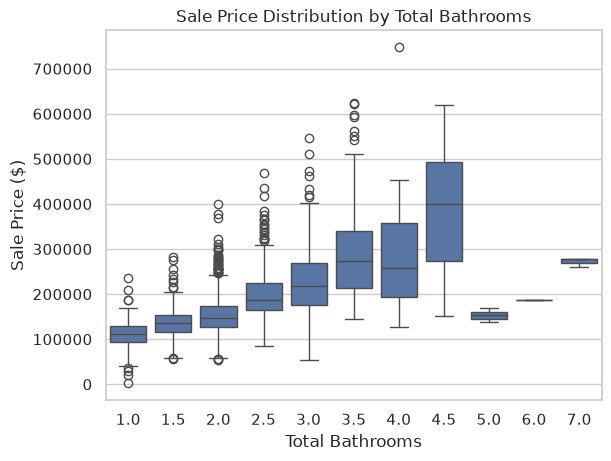

In [14]:
# Question 2b
sns.boxplot(data=ames_data_with_bathrooms, x="total_bathrooms", y="SalePrice")

plt.title('Sale Price Distribution by Total Bathrooms')
plt.xlabel('Total Bathrooms')
plt.ylabel('Sale Price ($)')
plt.show()

## Question 3

In [15]:
from sklearn.model_selection import train_test_split

# Question 3a
train, test = train_test_split(ames_data, test_size=0.3, random_state=0)

In [16]:
print(f"Q3a Answer - Training observations: {len(train)}")
print(f"Test observations: {len(test)}")

print(
    "Total observations preserved:",
    len(train) + len(test) == len(ames_data)
)

print(
    f"Training proportion: {len(train) / len(ames_data):.2f}"
)
print(
    f"Test proportion: {len(test) / len(ames_data):.2f}"
)

Q3a Answer - Training observations: 1400
Test observations: 600
Total observations preserved: True
Training proportion: 0.70
Test proportion: 0.30


In [17]:
def prepare_baseline_data(data):
    """Prepare predictors and target for the baseline regression model."""
    
    prepared = remove_outliers(
        data,
        "Gr_Liv_Area",
        upper=5000
    )
    
    prepared = add_total_bathrooms(prepared)
    
    feature_columns = [
        "Gr_Liv_Area",
        "Garage_Area",
        "total_bathrooms"
    ]
    
    X = prepared[feature_columns].copy()
    y = prepared["SalePrice"].copy()
    
    return X, y

In [18]:
# Prepare the training data
X_train, y_train = prepare_baseline_data(train)

print(X_train.shape)
X_train.head()

(1400, 3)


,Gr_Liv_Area,Garage_Area,total_bathrooms
1719,1050,368,2.0
1702,1452,506,3.5
1287,1280,432,2.5
482,1306,472,1.5
768,1677,627,3.5


In [19]:
from sklearn.linear_model import LinearRegression

# Question 3b
linear_model = LinearRegression()

In [20]:
# Verification - do not modify
print(
    "Q3b Answer - Model type:",
    type(linear_model).__name__
)

print(
    "Fit intercept:",
    linear_model.fit_intercept
)

Q3b Answer - Model type: LinearRegression
Fit intercept: True


In [21]:
# Question 3c
linear_model.fit(X_train, y_train)

y_fitted = linear_model.predict(X_train)

In [22]:
# Verification - do not modify
print(
    "Q3c Answer - Number of fitted values:",
    len(y_fitted)
)

print(
    "Matches training observations:",
    len(y_fitted) == len(y_train)
)

Q3c Answer - Number of fitted values: 1400
Matches training observations: True


In [23]:
# Question 3d
def rmse(actual, predicted):
    """Calculate root mean squared error."""
    
    return np.sqrt(np.mean((actual - predicted) ** 2))

In [24]:
# Verification - do not modify
example_actual = np.array([100, 200, 300])
example_predicted = np.array([110, 190, 310])

print(
    f"Q3d Answer - Example RMSE: "
    f"{rmse(example_actual, example_predicted):.2f}"
)

Q3d Answer - Example RMSE: 10.00


In [25]:
# Question 3e

training_rmse = rmse(train["SalePrice"], y_fitted)

print(f"Training RMSE: ${training_rmse:,.0f}")

Training RMSE: $44,333


In [26]:
X_train_no_bath = X_train.drop(columns="total_bathrooms")

linear_model_no_bath = LinearRegression()

# Fit the model
linear_model_no_bath.fit(X_train_no_bath, y_train)

# Generate fitted value
y_fitted_no_bath = linear_model_no_bath.predict(X_train_no_bath)

# Calculate training RMSE
training_rmse_no_bath = rmse(train["SalePrice"], y_fitted_no_bath)

print(
    f"Training RMSE with total_bathrooms: "
    f"${training_rmse:,.0f}"
)

print(
    f"Training RMSE without total_bathrooms: "
    f"${training_rmse_no_bath:,.0f}"
)

Training RMSE with total_bathrooms: $44,333
Training RMSE without total_bathrooms: $47,040


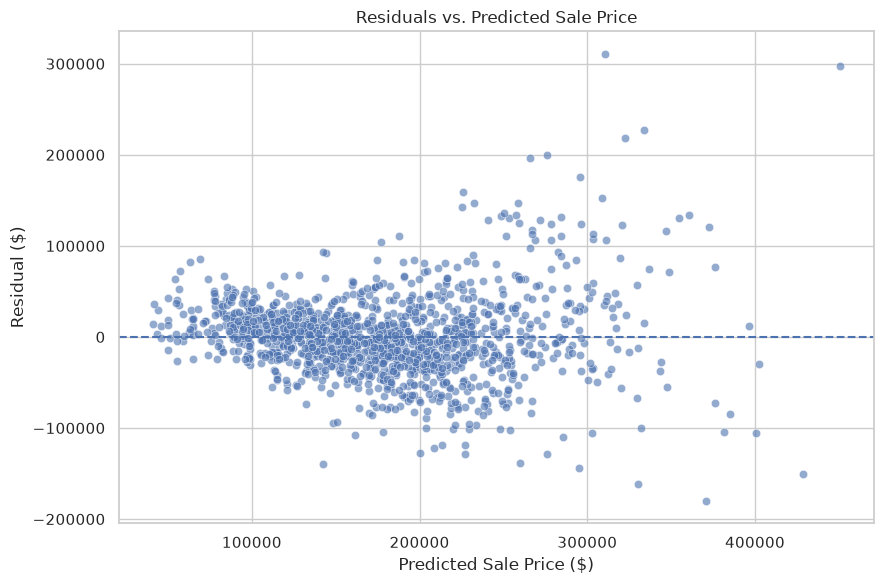

In [27]:
# Calculate training residuals
training_residuals = y_train - y_fitted

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_fitted,
    y=training_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs. Predicted Sale Price")

plt.tight_layout()
plt.show()

## Question 3g — Interpreting the Baseline Model

Examine the residual plot.

Describe at least **two ways** the current regression model might be improved.

For each suggestion, explain why it could help improve prediction.

Consider ideas such as:

- adding informative predictors,
- representing nonlinear relationships,
- incorporating categorical variables, or
- engineering features from existing variables.

Do not use the test set when proposing or evaluating these changes.

**Your answer:**

*At this moment, we only use 3 predictors for the price, but the price of a home is dictated by a lot more. Those predictors are good, but can have outliers and adding more would help create a better model.* 

*An important predictor that we haven't consider is the categorical variable of the neighbourhood where the house is found. Usually, the neighbourhood is a really good indicator of how expensive a house will be as house prices are often decided by comparing the house with similar houses found in the neighbourhood.* 

## Question 4

In [28]:
from sklearn.model_selection import KFold
from sklearn.base import clone

# Question 4

def cross_validate_rmse(model, X, y):
    """Return validation RMSE values from 5-fold cross-validation."""
    
    # Create the 5-fold splitter
    kfold = KFold(n_splits=5, shuffle=True, random_state=0)
    
    rmse_values = []
    
    # Iterate through the cross-validation folds
    for train_index, val_index in kfold.split(X):

        # Split the current fold into training and validation data
        X_fold_train = X.iloc[train_index]
        X_fold_val = X.iloc[val_index]

        y_fold_train = y.iloc[train_index]
        y_fold_val = y.iloc[val_index]

        # Fit a fresh copy of the model
        fold_model = clone(model)
        fold_model.fit(X_fold_train, y_fold_train)

        # Predict on the validation fold
        y_fold_predicted = fold_model.predict(X_fold_val)

        # Store validation RMSE
        rmse_values.append(np.sqrt(np.mean((y_fold_val - y_fold_predicted) ** 2)))

    return rmse_values

In [29]:
# Verification - do not modify

cv_scores = cross_validate_rmse(
    model=LinearRegression(),
    X=X_train,
    y=y_train
)

print(f"Q4 Answer - Number of folds: {len(cv_scores)}")

print(
    "Cross-validation RMSE scores:",
    [round(score, 0) for score in cv_scores]
)

print(
    f"Mean cross-validation RMSE: "
    f"${np.mean(cv_scores):,.0f}"
)

print(
    f"Standard deviation: "
    f"${np.std(cv_scores):,.0f}"
)

Q4 Answer - Number of folds: 5
Cross-validation RMSE scores: [np.float64(48330.0), np.float64(41335.0), np.float64(41471.0), np.float64(43947.0), np.float64(47421.0)]
Mean cross-validation RMSE: $44,501
Standard deviation: $2,922


In [30]:
# Cross-validation with total_bathrooms
cv_scores_with_bath = cross_validate_rmse(
    LinearRegression(),
    X_train,
    y_train
)

# Cross-validation without total_bathrooms
cv_scores_no_bath = cross_validate_rmse(
    LinearRegression(),
    X_train_no_bath,
    y_train
)

print(
    f"Mean CV RMSE with total_bathrooms: "
    f"${np.mean(cv_scores_with_bath):,.0f}"
)

print(
    f"Mean CV RMSE without total_bathrooms: "
    f"${np.mean(cv_scores_no_bath):,.0f}"
)

print(
    f"Difference: "
    f"${np.mean(cv_scores_no_bath) - np.mean(cv_scores_with_bath):,.0f}"
)

Mean CV RMSE with total_bathrooms: $44,501
Mean CV RMSE without total_bathrooms: $47,144
Difference: $2,644


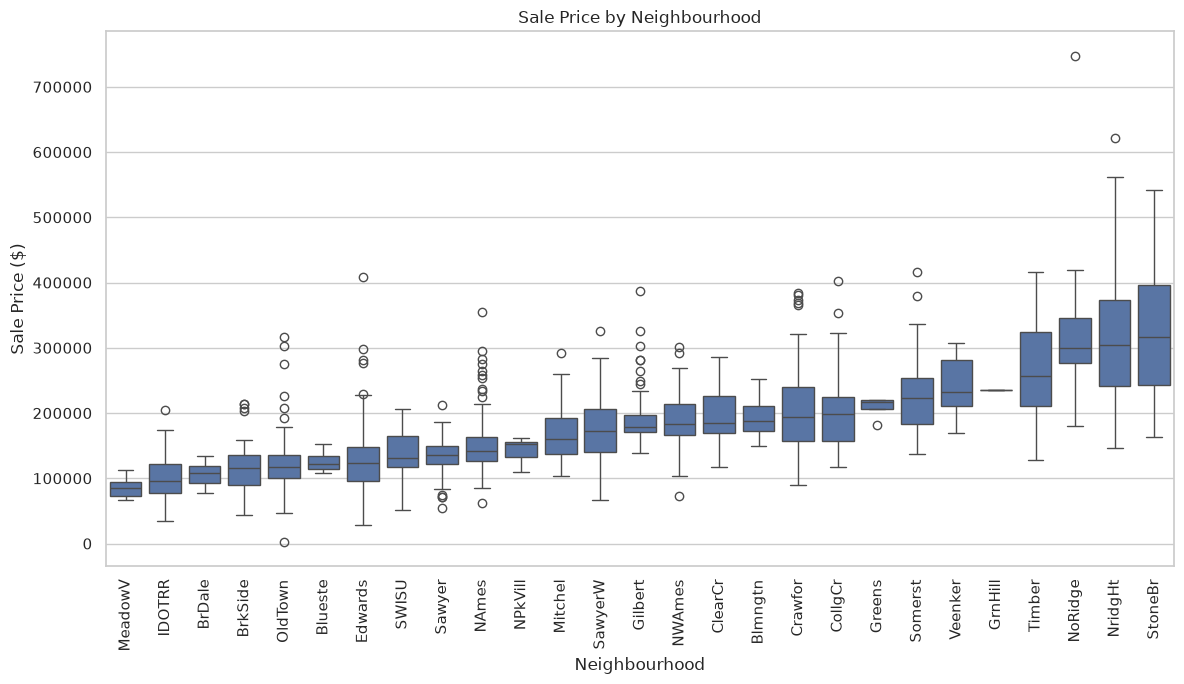

In [31]:
# Order neighbourhoods by median SalePrice in the training data
neighborhood_order = (
    train
    .groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=train,
    x="Neighborhood",
    y="SalePrice",
    order=neighborhood_order
)

plt.xticks(rotation=90)
plt.xlabel("Neighbourhood")
plt.ylabel("Sale Price ($)")
plt.title("Sale Price by Neighbourhood")

plt.tight_layout()
plt.show()

## Question 5

## Question 5a — Interpreting Neighbourhood Effects

Based on the visualization above, describe the relationship between `Neighborhood` and `SalePrice`.

In your answer, comment on:

1. whether typical sale prices appear to differ across neighbourhoods, and
2. why `Neighborhood` might provide useful information to a regression model.

**Your answer:**

1. Sales price tend to varies per neighbourhood, some neighbourhoods have a higher median price and a larger variation in price, some neighbourhood have more outliers.

2. In cities, some neighbourhood tend to be more prized by the people (closer to ammenities, bigger houses, etc.) they will correlate with higher prices.

In [32]:
# Examine fireplace quality values in the training data
train["Fireplace_Qu"].value_counts(dropna=False)

Fireplace_Qu
NaN    697
Gd     352
TA     275
Fa      34
Ex      23
Po      19
Name: count, dtype: int64

In [33]:
# Question 5b

missing_fireplace_count = train["Fireplace_Qu"].isna().sum()
missing_fireplace_percent = missing_fireplace_count / len(train) * 100

print(
    f"Missing Fireplace_Qu values: "
    f"{missing_fireplace_count}"
)

print(
    f"Percentage missing: "
    f"{missing_fireplace_percent:.1f}%"
)

Missing Fireplace_Qu values: 697
Percentage missing: 49.8%


In [34]:
# Verification - do not modify
print(
    "Q5b Answer - Count is valid:",
    0 <= missing_fireplace_count <= len(train)
)

print(
    "Percentage is valid:",
    0 <= missing_fireplace_percent <= 100
)

Q5b Answer - Count is valid: True
Percentage is valid: True


In [35]:
# Question 5c

def prepare_fireplace_quality(data):
    """Return a copy with missing fireplace quality labelled explicitly."""
    
    # Create a copy of the input DataFrame.
    prepared = data.copy()
    
    # Replace missing Fireplace_Qu values.
    prepared["Fireplace_Qu"] = prepared["Fireplace_Qu"].fillna("No Fireplace")
    
    return prepared

In [36]:
# Verification - do not modify
fireplace_check = prepare_fireplace_quality(train)

print(
    "Q5c Answer - Missing values remaining:",
    fireplace_check["Fireplace_Qu"].isna().sum()
)

print(
    "'No Fireplace' category present:",
    "No Fireplace" in fireplace_check["Fireplace_Qu"].unique()
)

print(
    "Original training data unchanged:",
    train["Fireplace_Qu"].isna().sum() > 0
)

Q5c Answer - Missing values remaining: 0
'No Fireplace' category present: True
Original training data unchanged: True


In [37]:
# Question 5d

numeric_features = [
    "Gr_Liv_Area",
    "Garage_Area",
    "total_bathrooms"
]

categorical_features = [
    "Neighborhood",
    "Fireplace_Qu"
]

In [38]:
# Verification - do not modify
print(
    "Q5d Answer - Numerical features:",
    numeric_features
)

print(
    "Categorical features:",
    categorical_features
)

Q5d Answer - Numerical features: ['Gr_Liv_Area', 'Garage_Area', 'total_bathrooms']
Categorical features: ['Neighborhood', 'Fireplace_Qu']


In [43]:
# Prepare a working copy of the training data
train_improved = remove_outliers(
    train,
    "Gr_Liv_Area",
    upper=5000
)

train_improved = add_total_bathrooms(
    train_improved
)

train_improved = prepare_fireplace_quality(
    train_improved
)

X_train_improved = train_improved[
    numeric_features + categorical_features
].copy()

y_train_improved = train_improved[
    "SalePrice"
].copy()

X_train_improved.head()

,Gr_Liv_Area,Garage_Area,total_bathrooms,Neighborhood,Fireplace_Qu
1719,1050,368,2.0,NAmes,No Fireplace
1702,1452,506,3.5,Somerst,No Fireplace
1287,1280,432,2.5,NAmes,TA
482,1306,472,1.5,OldTown,No Fireplace
768,1677,627,3.5,SawyerW,No Fireplace


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Question 5e

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

In [41]:
# Verification - do not modify

X_train_transformed = preprocessor.fit_transform(
    X_train_improved
)

print(
    "Q5e Answer - Original feature count:",
    X_train_improved.shape[1]
)

print(
    "Transformed feature count:",
    X_train_transformed.shape[1]
)

print(
    "Number of observations preserved:",
    X_train_transformed.shape[0]
    == X_train_improved.shape[0]
)

Q5e Answer - Original feature count: 5
Transformed feature count: 34
Number of observations preserved: True


In [42]:
# Inspect the names of the transformed predictors
transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

transformed_feature_names[:15]

array(['numeric__Gr_Liv_Area', 'numeric__Garage_Area',
       'numeric__total_bathrooms', 'categorical__Neighborhood_Blueste',
       'categorical__Neighborhood_BrDale',
       'categorical__Neighborhood_BrkSide',
       'categorical__Neighborhood_ClearCr',
       'categorical__Neighborhood_CollgCr',
       'categorical__Neighborhood_Crawfor',
       'categorical__Neighborhood_Edwards',
       'categorical__Neighborhood_Gilbert',
       'categorical__Neighborhood_Greens',
       'categorical__Neighborhood_GrnHill',
       'categorical__Neighborhood_IDOTRR',
       'categorical__Neighborhood_MeadowV'], dtype=object)

## Question 6

In [44]:
from sklearn.pipeline import Pipeline

# Question 6

improved_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ]
)

improved_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

In [45]:
# Verification - do not modify
print(
    "Q6a Answer - Object type:",
    type(improved_model).__name__
)

print(
    "Pipeline steps:",
    list(improved_model.named_steps.keys())
)

print(
    "Final estimator:",
    type(improved_model.named_steps["regression"]).__name__
)

Q6a Answer - Object type: Pipeline
Pipeline steps: ['preprocessor', 'regression']
Final estimator: LinearRegression


In [46]:
# Question 6b

cv_scores_improved = cross_validate_rmse(
    model=improved_model,
    X=X_train_improved,
    y=y_train_improved
)

baseline_cv_rmse = np.mean(cv_scores)

improved_cv_rmse = np.mean(cv_scores_improved)

cv_improvement = improved_cv_rmse - baseline_cv_rmse

print(
    "Improved-model CV RMSE scores:",
    [round(score) for score in cv_scores_improved]
)

print(
    f"\nBaseline mean CV RMSE: "
    f"${baseline_cv_rmse:,.0f}"
)

print(
    f"Improved mean CV RMSE: "
    f"${improved_cv_rmse:,.0f}"
)

print(
    f"Reduction in mean CV RMSE: "
    f"${cv_improvement:,.0f}"
)

Improved-model CV RMSE scores: [38762, 36913, 33193, 33298, 38699]

Baseline mean CV RMSE: $44,501
Improved mean CV RMSE: $36,173
Reduction in mean CV RMSE: $-8,328


/home/zoik/anaconda3/envs/science/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## Question 7

I have chosen the Overall_Qual as an additional predictor because people are usually influenced by the look of an house and the overall material and finish quality of a house usually makes the house looks better, hence should call for an higher price

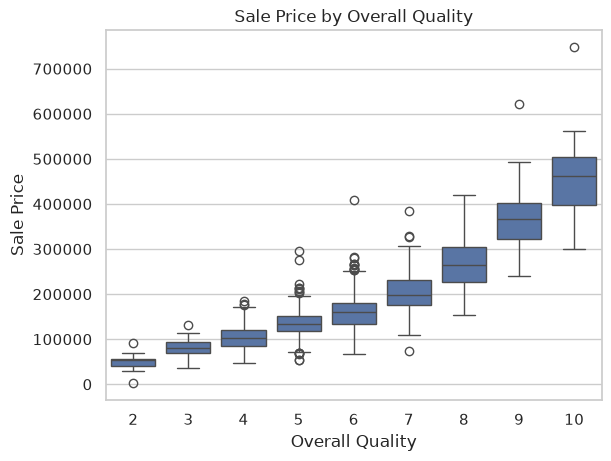

Overall_Qual
2      53900.0
3      80600.0
4     103650.0
5     133900.0
6     161000.0
7     197400.0
8     264550.0
9     366500.0
10    461525.0
Name: SalePrice, dtype: float64


In [50]:
sns.boxplot(data=train, x="Overall_Qual", y="SalePrice")

plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

print(train.groupby("Overall_Qual")["SalePrice"].median())

Overall the quality seems to impact the sale price of a house

In [53]:
# Creating the fianl categories and X/

numeric_features_final = numeric_features.copy()

categorical_features_final = categorical_features + [
    "Overall_Qual"
]

X_train_final = train_improved[
    numeric_features_final + categorical_features_final
].copy()

y_train_final = train_improved["SalePrice"].copy()

In [54]:
# Using columnTransformer on the new categorical features

final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features_final
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features_final
        )
    ],
    remainder="drop"
)

In [55]:
# Creating the final model

final_model = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        ("regression", LinearRegression())
    ]
)

In [58]:
# Evaluating the final model

cv_scores_final = cross_validate_rmse(
    model=final_model,
    X=X_train_final,
    y=y_train_final
)

final_cv_rmse = np.mean(cv_scores_final)

print("Final CV RMSE scores:", cv_scores_final)

print(f"Final mean CV RMSE: ${final_cv_rmse:,.0f}")

Final CV RMSE scores: [np.float64(33034.41926455135), np.float64(29516.48564724892), np.float64(27705.757607040705), np.float64(29440.802776649965), np.float64(31391.223414601453)]
Final mean CV RMSE: $30,218


/home/zoik/anaconda3/envs/science/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [59]:
# Verification - do not modify
print(
    "Five CV scores produced:",
    len(cv_scores_final) == 5
)

print(
    f"Improved-model mean CV RMSE: "
    f"${improved_cv_rmse:,.0f}"
)

print(
    f"Final-model mean CV RMSE: "
    f"${final_cv_rmse:,.0f}"
)

Five CV scores produced: True
Improved-model mean CV RMSE: $36,173
Final-model mean CV RMSE: $30,218


## Question 8

In [61]:
# Question 8

# Apply the deterministic feature-engineering steps
# used by your final model.
final_test_data = remove_outliers(
    test,
    "Gr_Liv_Area",
    upper=5000
)

final_test_data = add_total_bathrooms(final_test_data)

final_test_data = prepare_fireplace_quality(final_test_data)

# Select the test predictors.
X_test = final_test_data[
    numeric_features_final + categorical_features_final
].copy()

# Select the test target.
y_test = final_test_data["SalePrice"].copy()

# Fit the selected final model using all training data.
final_model.fit(X_train_final, y_train_final)

# Predict the held-out test set.
y_test_predicted = final_model.predict(X_test)

# Calculate final test RMSE.
test_rmse = np.sqrt(
    np.mean((y_test - y_test_predicted) ** 2)
)

print(
    f"Final cross-validation RMSE: "
    f"${final_cv_rmse:,.0f}"
)

print(
    f"Final test RMSE: "
    f"${test_rmse:,.0f}"
)

Final cross-validation RMSE: $30,218
Final test RMSE: $33,858


/home/zoik/anaconda3/envs/science/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [62]:
# Verification - do not modify
print(
    "Q8 Answer - All test observations retained:",
    len(y_test) == len(test)
)

print(
    "Predictions match test observations:",
    len(y_test_predicted) == len(y_test)
)

print(
    "Test RMSE is positive:",
    test_rmse > 0
)

Q8 Answer - All test observations retained: False
Predictions match test observations: True
Test RMSE is positive: True
